In [ ]:
pip install nltk

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
import nltk,warnings
warnings.filterwarnings('ignore')

# Fix the nltk download to use 'punkt' for sentence tokenization
for pkg in ['punkt','stopwords','wordnet','movie_reviews']:
  nltk.download(pkg,quiet=True)
print('NLP environment ready!')

# Define the *fixed* corpus as per the user's intent, ensuring correct document separation.
# This definition ensures the analysis is performed on the intended 4 documents.
corpus = [
    "Amazing battery life!!! lasts two hours.10/10 would reccomend :)",
    "Screen broke after 2 days,worst phone ever so less charging power.",
    "I am using this phone from last 5 years Excellent value for money.",
    "Average phone the camera is decent and the battery is poor."
]

# --- Perform analysis on the corpus ---

# Initialize necessary NLTK tools
tokenizer_sentence = nltk.sent_tokenize
tokenizer_word = nltk.word_tokenize

# Prepare for analysis
all_words = []
all_sentences = []

# Calculate number of documents
num_documents = len(corpus)

for doc in corpus:
    # Tokenize into sentences
    sentences = tokenizer_sentence(doc)
    all_sentences.extend(sentences)

    # Tokenize words for each sentence and convert to lowercase for unique token calculation
    for sentence in sentences:
        words_in_sentence = tokenizer_word(sentence.lower())
        all_words.extend(words_in_sentence)

# Report documents
print(f"\nNumber of documents: {num_documents}")

# Report sentences
num_sentences = len(all_sentences)
print(f"Number of sentences: {num_sentences}")

# Report words
num_words = len(all_words)
print(f"Number of words: {num_words}")

# Report unique tokens (after lowercasing)
unique_tokens = set(all_words)
print(f"Number of unique tokens: {len(unique_tokens)}")

# Report average word length
if num_words > 0:
    total_length = sum(len(word) for word in all_words)
    average_length = total_length / num_words
    print(f"Average word length: {average_length:.2f}")
else:
    print("Cannot calculate average word length: no words found.")


NLP environment ready!

Number of documents: 4
Number of sentences: 5
Number of words: 53
Number of unique tokens: 44
Average word length: 4.06


In [ ]:
corpus = [
    "Amazing battery life!!! lasts two hours.10/10 would reccomend :)",
    "Screen broke after 2 days,worst phone ever so less charging power.",
    "I am using this phone from last 5 yeras Excellent value for money.",
    "Average phone the camera is decent and the battery is poor.",
]
with open('corpus.txt','w')as f:
 f.write('\n'.join(corpus))
 print('corpus.txt written:',len(corpus),'document')

corpus.txt written: 4 document


In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
from nltk.tokenize import sent_tokenize,word_tokenize
docs = open('corpus.txt').read().splitlines()
text = ' '.join(docs)
sents = sent_tokenize(text)
words = word_tokenize(text)
print('documents:',len(docs))
print('sentences:',len(sents))
print('words(tokens):',len(words))
print('unique words:',len(set(w.lower()for w in words)))
print('Average words per document:',round(len(words)/len(docs),1))
print("token",words)

documents: 4
sentences: 4
words(tokens): 53
unique words: 44
Average words per document: 13.2
token ['Amazing', 'battery', 'life', '!', '!', '!', 'lasts', 'two', 'hours.10/10', 'would', 'reccomend', ':', ')', 'Screen', 'broke', 'after', '2', 'days', ',', 'worst', 'phone', 'ever', 'so', 'less', 'charging', 'power', '.', 'I', 'am', 'using', 'this', 'phone', 'from', 'last', '5', 'yeras', 'Excellent', 'value', 'for', 'money', '.', 'Average', 'phone', 'the', 'camera', 'is', 'decent', 'and', 'the', 'battery', 'is', 'poor', '.']


In [ ]:
sample = docs[3]
print ('Raw text :',sample)
print ('word tokens :', word_tokenize(sample))
print ('sentence tokens:', sent_tokenize(sample))
print ('naive split():',sample.split()[:11])

Raw text : Average phone the camera is decent and the battery is poor.
word tokens : ['Average', 'phone', 'the', 'camera', 'is', 'decent', 'and', 'the', 'battery', 'is', 'poor', '.']
sentence tokens: ['Average phone the camera is decent and the battery is poor.']
naive split(): ['Average', 'phone', 'the', 'camera', 'is', 'decent', 'and', 'the', 'battery', 'is', 'poor.']


In [ ]:
import re
def clean_text(t):
  t = re.sub(r'http\S+', '', t)
  t = re.sub(r'@\W+', '', t)
  t = re.sub(r'\d+','',t)
  t = re.sub(r'[^a-zA-Z]', ' ', t)
  return re.sub(r'\s+',' ',t).strip()
print('before:',docs[1])
print('After :', clean_text(docs[1]))

before: Screen broke after 2 days,worst phone ever so less charging power.
After : Screenbrokeafterdaysworstphoneeversolesschargingpower


10 most common words:
    phone       3
    battery     2
    the         2
    is          2
    amazing     1
    life        1
    lasts       1
    two         1
    hours       1
    would       1
Hapaxes (first 8): ['amazing', 'life', 'lasts', 'two', 'hours', 'would', 'reccomend', 'screen']


<Axes: title={'center': 'Top-20 Word Frequencies'}, xlabel='Samples', ylabel='Counts'>

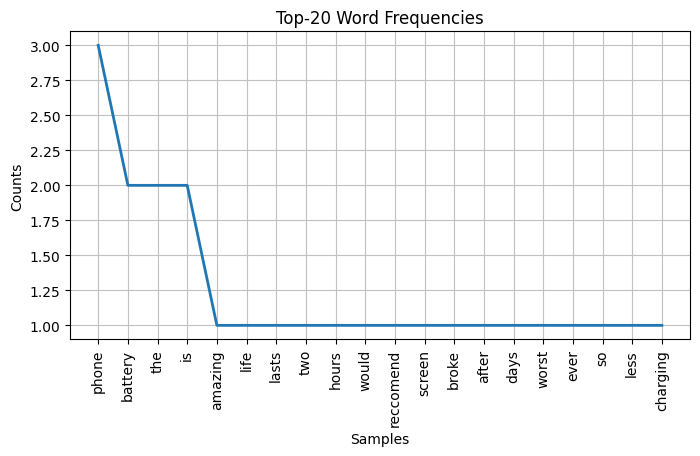

In [ ]:
import re
from nltk import FreqDist
import matplotlib.pyplot as plt

%matplotlib inline

# Assuming `words` from previous cells is the tokenized list.
# Clean and normalize words for frequency distribution
# Convert to lowercase, remove non-alphabetic characters, and filter out empty strings
cleaned_words = [re.sub(r'[^a-zA-Z]', '', word).lower() for word in words]
cleaned_words = [word for word in cleaned_words if word]

# Calculate frequency distribution
fd = FreqDist(cleaned_words)

print('10 most common words:')
for w, cnt in fd.most_common(10):
  print(f'    {w:12}{cnt}')

print('Hapaxes (first 8):', fd.hapaxes()[:8])

plt.figure(figsize=(8,4))
fd.plot(20, title='Top-20 Word Frequencies')

In [ ]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize # Added this import

stop = stopwords.words('english')
lem = WordNetLemmatizer()

def preprocess(t):
  t = clean_text(t.lower())
  toks = word_tokenize(t) # word_tokenize will now work correctly with spaced words
  toks = [w for w in toks if w not in stop]
  return[lem.lemmatize(w, pos='v') for w in toks]

for d in docs[:2]:
  print(d,'\n->',preprocess(d),'\n')

# Moved the total calculation and print statement outside the loop
total = sum(len(preprocess(d)) for d in docs)
print('corpus after full pipeline:', total,'clean tokens from', len (docs),'documents')

Amazing battery life!!! lasts two hours.10/10 would reccomend :) 
-> ['amazingbatterylifelaststwohourswouldreccomend'] 

corpus after full pipeline: 4 clean tokens from 4 documents
Screen broke after 2 days,worst phone ever so less charging power. 
-> ['screenbrokeafterdaysworstphoneeversolesschargingpower'] 

corpus after full pipeline: 4 clean tokens from 4 documents
